In [1]:
import numpy as np
seed = 123
np.random.seed(seed)

def gen_data(tp:int, fp: int, tn: int, fn: int):
    num_postive = (tp + fn)
    num_negative = (fp + tn)
    total_size = num_postive + num_negative
    y_true = np.zeros(total_size, int)
    pos_indx = np.random.choice(np.arange(total_size), size=(num_postive), replace=False)
    neg_indx = np.array(list(set(np.arange(total_size)) - set(pos_indx)))
    y_true[pos_indx] = 1
    y_pred = y_true.copy()
    fp_indx = np.random.choice(neg_indx, fp, replace=False)
    fn_indx = np.random.choice(pos_indx, fn, replace=False)
    y_pred[fp_indx] = 1
    y_pred[fn_indx] = 0
    return (y_true, y_pred)

In [2]:
y_true, y_pred = gen_data(tp=10, fp=0, tn=900, fn=90)

In [3]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
tp, fp, tn, fn

(np.int64(10), np.int64(0), np.int64(900), np.int64(90))

## Accuracy

In [4]:
def acc(y_true, y_pred):
    """
    y_true: nhãn dữ liệu
    y_pred: kết quả dự đoán từ mô hình
    """
    correct = np.sum(y_true == y_pred)
    return correct/y_true.shape[0]

print('Accuracy = ', acc(y_true, y_pred))

Accuracy =  0.91


In [5]:
from sklearn.metrics import accuracy_score

print('Accuracy = ', accuracy_score(y_true, y_pred))

Accuracy =  0.91


## F1 score

In [6]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
precision = tp/(tp + fp) if tp + fp > 0 else 0.0
recall = tp/(tp + fn) if tp + fn > 0 else 0.0
f1_score = 2*precision*recall/(precision + recall) if precision + recall > 0 else 0.0

print('Precision = ', precision)
print('Recall = ', recall)
print('F1 score = ', round(f1_score, 4))

Precision =  1.0
Recall =  0.1
F1 score =  0.1818


In [7]:
from sklearn.metrics import f1_score, precision_score, recall_score

precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print('Precision = ', precision)
print('Recall = ', recall)
print('F1 score = ', round(f1, 4))

Precision =  1.0
Recall =  0.1
F1 score =  0.1818


# Precision-Recall Curve

In [8]:
from matplotlib import pyplot as plt

def plot_curve(xs, ys, title, xlabel, ylabel):
    plt.figure(figsize=(15, 7))
    plt.rcParams.update({'font.size': 15})
    plt.scatter(xs, ys, s=50, color="blue")
    plt.plot(xs, ys)
    plt.title(title, fontsize=20)
    plt.xlabel(xlabel, fontsize=15)
    plt.ylabel(ylabel, fontsize=15)
    plt.ylim(0, 1.1)

In [9]:
labels = [0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1]
y_pred = [0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1]
probs = [0.47, 0.65, 0.66, 0.64, 0.01, 0.37, 0.77, 0.31, 0.69, 0.10, 0.05, 0.66]

precision=array([0.41666667, 0.625     , 0.57142857, 0.66666667, 0.6       ,
       0.5       , 0.5       , 1.        , 1.        ])
recall=array([1. , 1. , 0.8, 0.8, 0.6, 0.4, 0.2, 0.2, 0. ])
thresholds=array([0.01, 0.37, 0.47, 0.64, 0.65, 0.66, 0.69, 0.77])


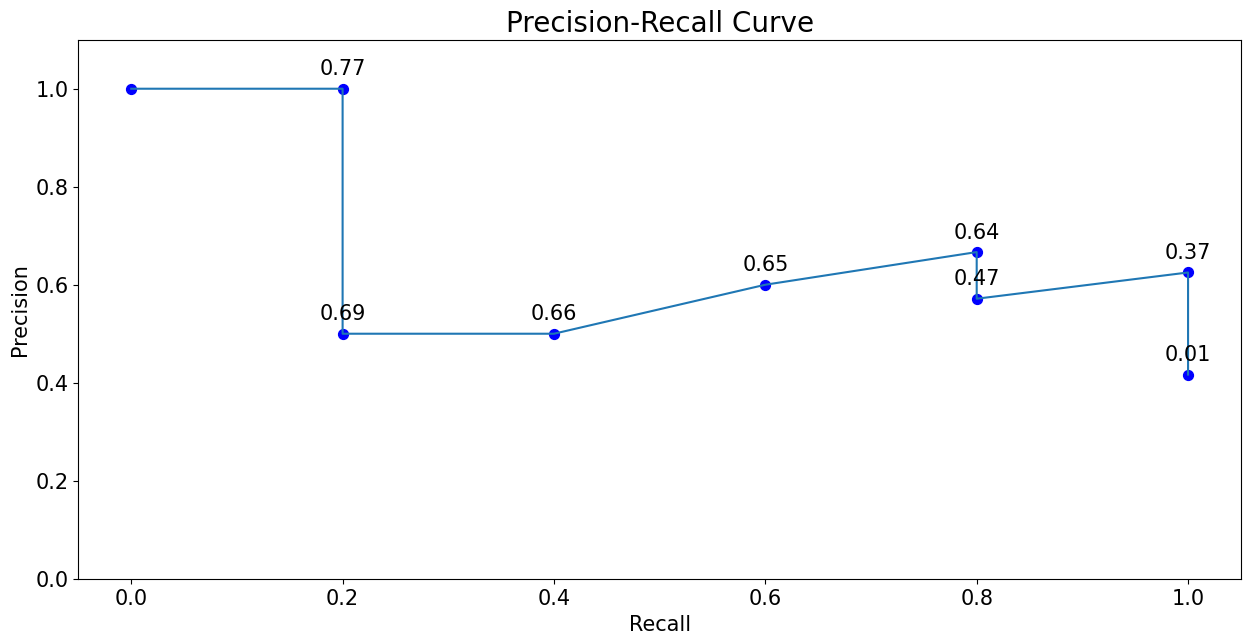

In [10]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(labels, probs, drop_intermediate=True)
print(f'{precision=}\n{recall=}\n{thresholds=}')
plot_curve(recall, precision, title="Precision-Recall Curve", xlabel="Recall", ylabel="Precision")
# show the value of the threshold
for i, threshold in enumerate(thresholds):
    plt.annotate(f"{threshold:.2f}", (recall[i], precision[i]), textcoords="offset points", xytext=(0,10), ha='center')

# ROC Curve

Dữ liệu cho bài toán bao gồm 
- labels: nhãn dữ liệu
- y_pred: giá trị mà mô hình dự đoán 
- probs: xác suất tương ứng với giá trị mà mô hình dự đoán
        y_pred = 1 nếu xác suất >= 0.5, ngược lại y_pred = 0

In [11]:
labels = [0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1]
y_pred = [0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1]
probs = [0.47, 0.65, 0.66, 0.64, 0.01, 0.37, 0.77, 0.31, 0.69, 0.10, 0.05, 0.66]
cl = [0, 1]

## ROC Curve with Sklearn

In [12]:
import sklearn.metrics as SK
fpr, tpr, thresholds = SK.roc_curve(labels, probs)
thresholds

array([ inf, 0.77, 0.69, 0.66, 0.64, 0.47, 0.37, 0.01])

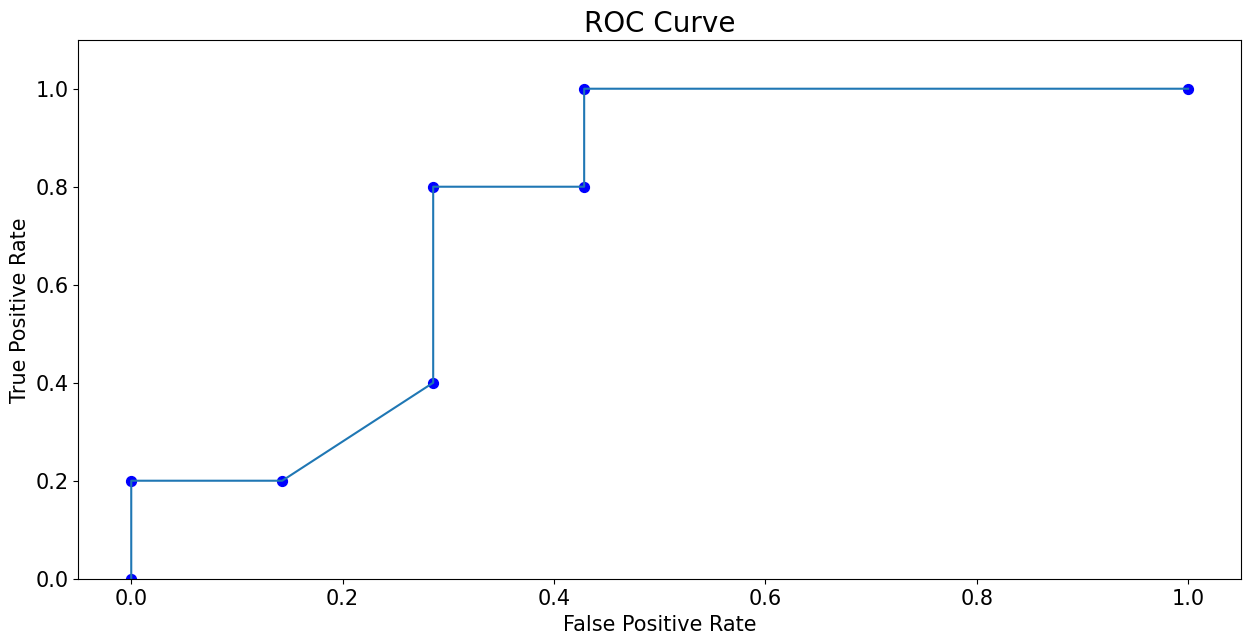

In [13]:
plot_curve(fpr, tpr, title="ROC Curve", xlabel="False Positive Rate", ylabel="True Positive Rate")

# AUC

## Implement by Python


In [14]:
def cal_AUC(tpr, fpr):
    trapz_area = 0
    for k in range(len(tpr) - 1):
      trapz_area += (fpr[k + 1] - fpr[k]) * (tpr[k  + 1] + tpr[k])/2.0
    return trapz_area
cal_AUC(tpr, fpr)

np.float64(0.7571428571428571)

Có thể dùng thư viện **np.trapz** 

In [15]:
np.trapz(tpr, fpr)

/var/folders/hd/bm192tk1117_lgdnw7f5yh_m0000gn/T/ipykernel_43468/224044759.py:1: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  np.trapz(tpr, fpr)


np.float64(0.7571428571428571)

## Implement by Sklearn

In [16]:
from sklearn.metrics import roc_auc_score
roc_auc_score(labels, probs)

np.float64(0.7571428571428571)

# MAE, MSE, RMSE, $R^2$

### Tạo dữ liệu

In [17]:
import random
random.seed(0)
np.random.seed(0)
x = [2.5, 1, 3, 2, 3.5, 4, 2.3, 3.6, 5, 4.5, 4.8, 3.4]
def fn(a):
    return 2 * a

y_true = list(map(fn, x))
y_true = y_true + np.random.normal(0,1,len(x))
print('Time x = ', x)
print('Score y = ', y_true)

Time x =  [2.5, 1, 3, 2, 3.5, 4, 2.3, 3.6, 5, 4.5, 4.8, 3.4]
Score y =  [6.76405235 2.40015721 6.97873798 6.2408932  8.86755799 7.02272212
 5.55008842 7.04864279 9.89678115 9.4105985  9.74404357 8.25427351]


### Plot dữ liệu

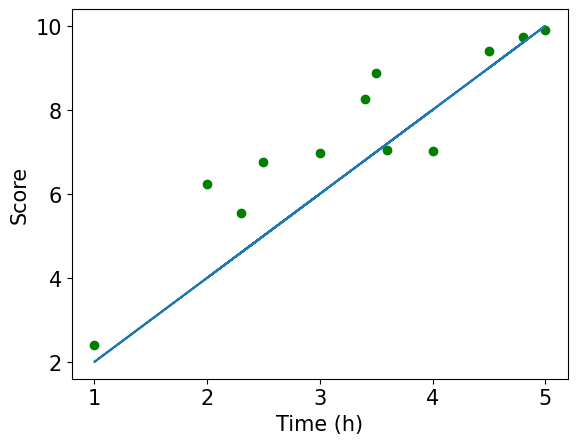

In [18]:
import matplotlib.pyplot as plt
plt.plot(x, y_true, 'go')
plt.xlabel('Time (h)')
plt.ylabel('Score')

y_pred = [i*2 for i in x]
plt.plot(x, y_pred)
plt.show()

## MAE

$$MAE = \frac{1}{n} \sum_{i}|y_i - \hat{y}_i| $$

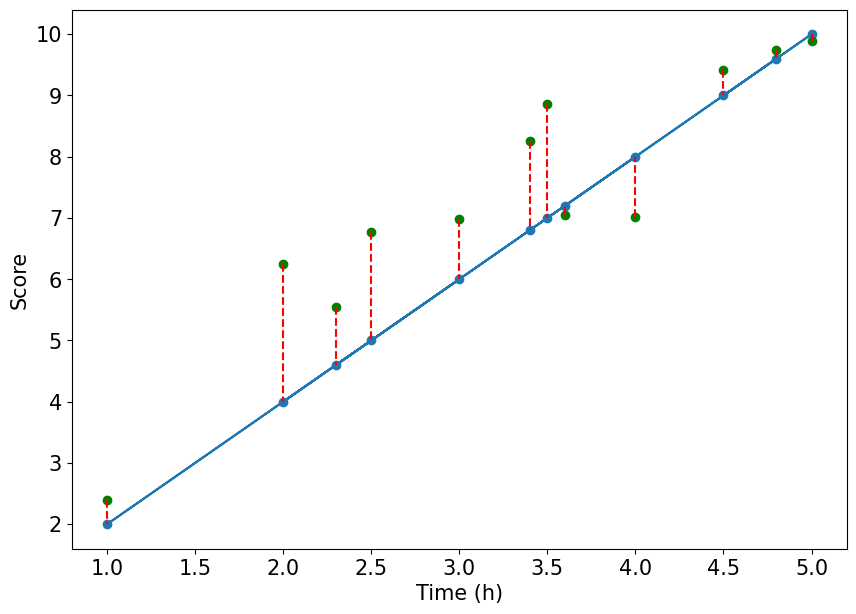

In [19]:
# Visualize MAE
plt.figure(figsize=(10, 7))
plt.plot(x, y_true, 'go')
plt.xlabel('Time (h)')
plt.ylabel('Score')
plt.plot(x, y_pred)
plt.scatter(x, y_pred)
for i in range(len(x)):
  plt.plot([x[i], x[i]], [y_true[i], y_pred[i]], 'r--')
plt.show()

### Implement by Python

In [20]:
import numpy as np

def mae(y_true, y_pred):
  y_true = np.array(y_true)
  y_pred = np.array(y_pred)
  return np.mean(np.abs(y_true - y_pred))

print(mae(y_true, y_pred))

0.953521388778961


### Implement by sklearn

In [21]:
from sklearn.metrics import mean_absolute_error
print(mean_absolute_error(y_true, y_pred))

0.953521388778961


## MSE

$$MSE = \frac{1}{n}\sum_i (y_i - \hat{y}_i) ^ 2$$

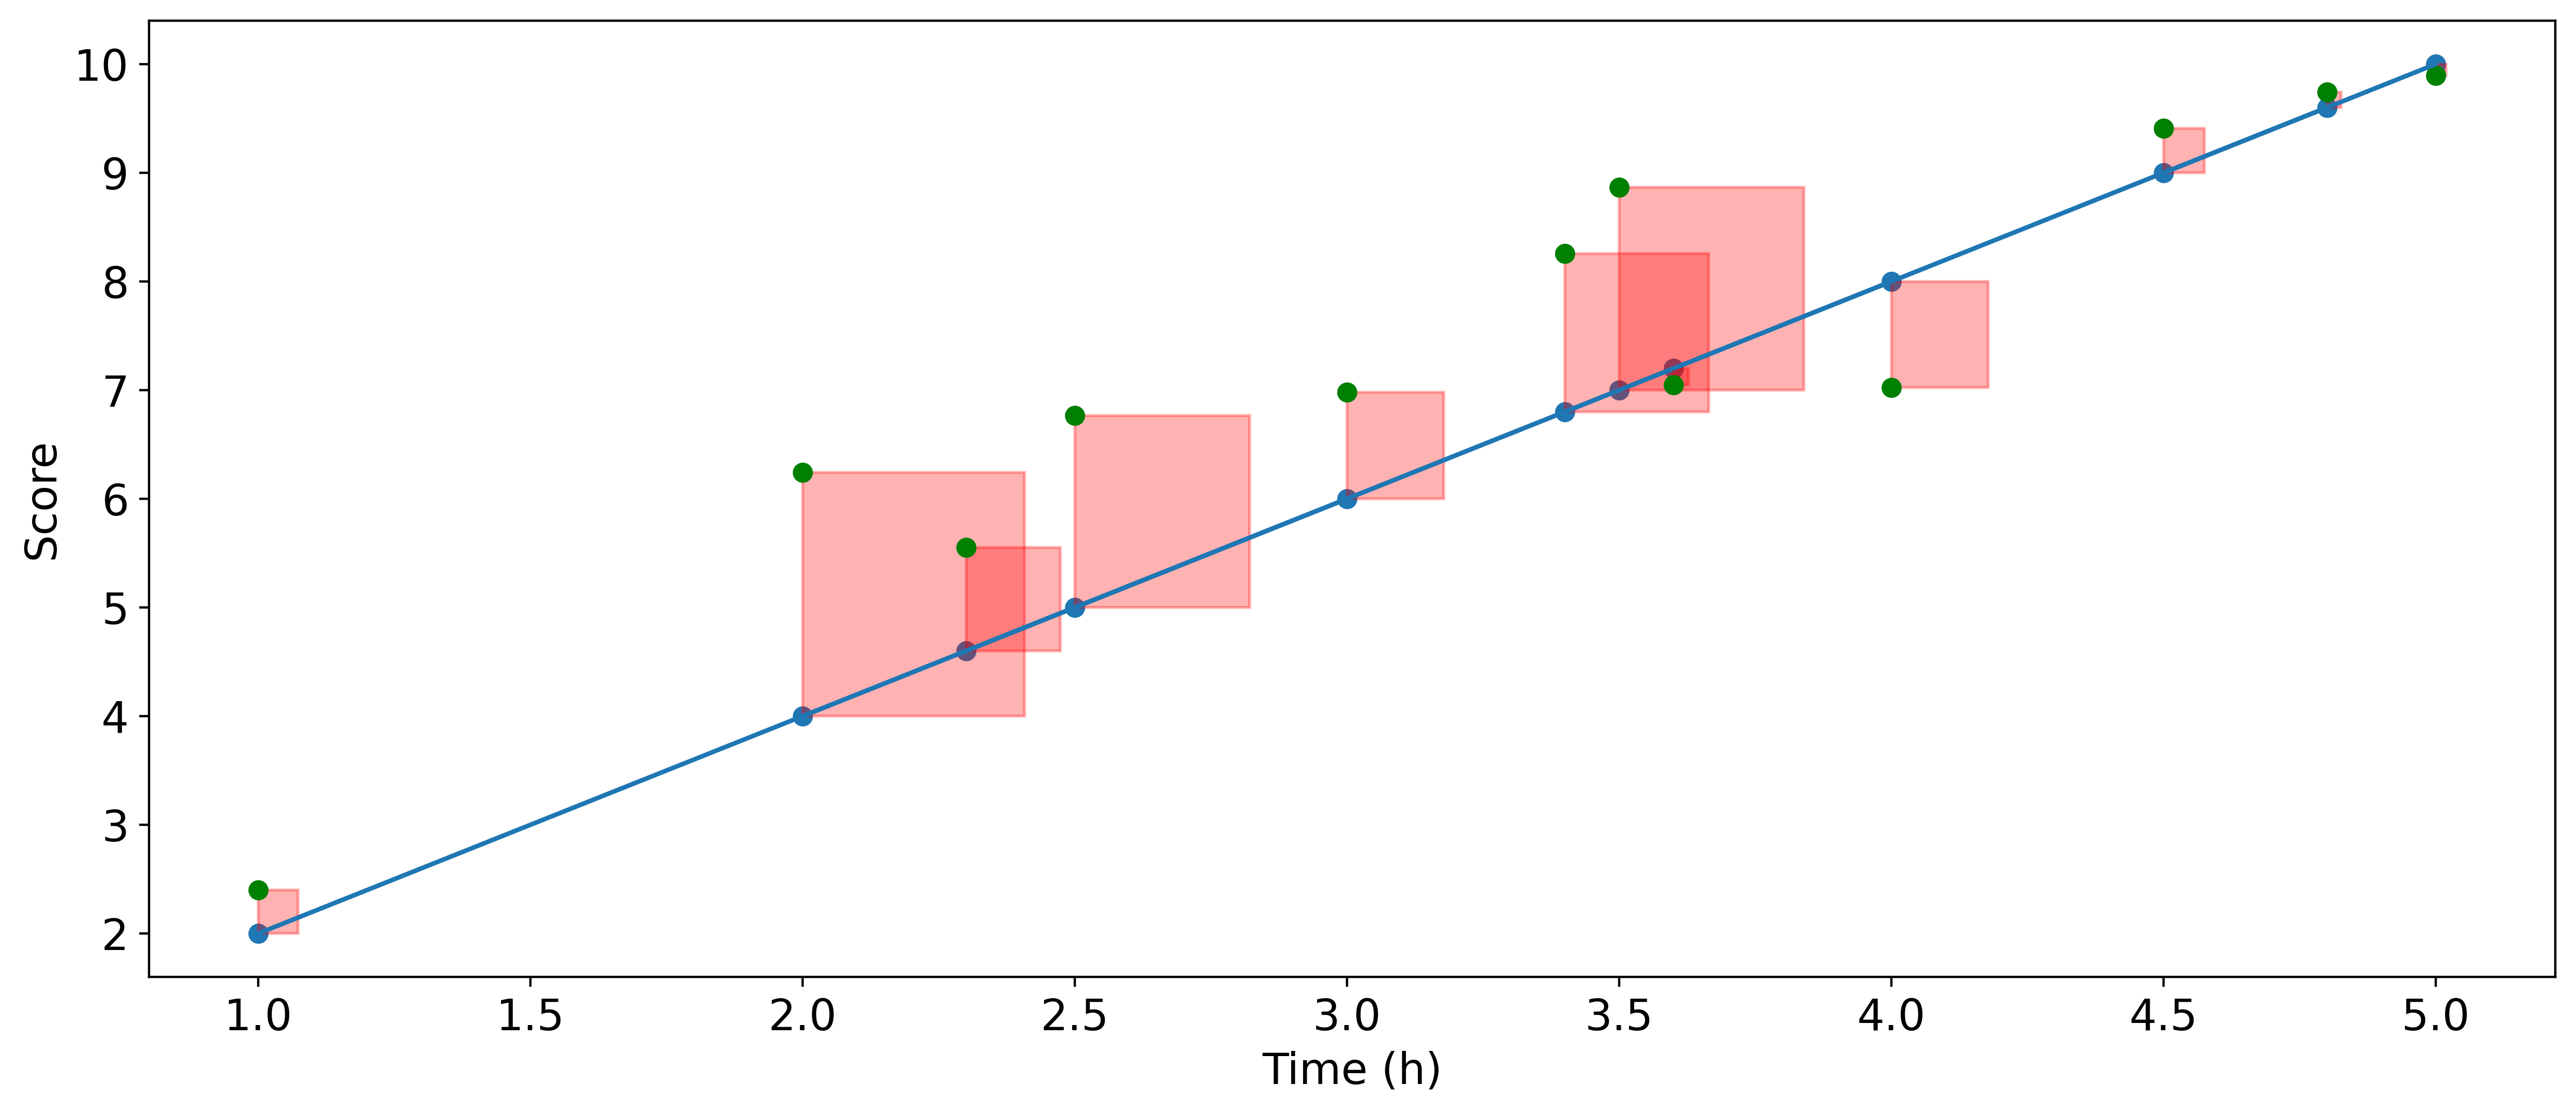

In [22]:
from matplotlib.patches import Rectangle
# Visualize MSE
plt.figure(figsize=(15, 6), dpi=400)
plt.plot(x, y_true, 'go')
plt.xlabel('Time (h)')
plt.ylabel('Score')
plt.plot(x, y_pred)
plt.scatter(x, y_pred)
for i in range(len(x)):
    error = (y_true[i] - y_pred[i])
    mae = abs(error) 
    if error > 0:
        point = (x[i], y_pred[i])
    else:
        point = (x[i], y_true[i])
    mse = Rectangle(point, mae/5.5, mae, linewidth=1, facecolor='r', edgecolor='r', alpha=0.3)
    ax = plt.gca()
    ax.add_patch(mse)
plt.show()

### Implement by Python

In [23]:
import numpy as np

def mse(y_true, y_pred):
  y_true = np.array(y_true)
  y_pred = np.array(y_pred)
  diff = y_true - y_pred
  squared_diff = np.square(diff)
  return squared_diff.mean()

print(mse(y_true, y_pred))

1.4112386661480356


### Implement by sklearn

In [24]:
from sklearn.metrics import mean_squared_error
print(mean_squared_error(y_true, y_pred))

1.4112386661480356


## RMSE

$$RMSE = \sqrt{MSE} =  \sqrt{\frac{1}{n}\sum_i (y_i - \hat{y}_i) ^ 2}$$

### Implement by Python

In [25]:
import numpy as np

def rmse(y_true, y_pred):
  y_true = np.array(y_true)
  y_pred = np.array(y_pred)
  diff = y_true - y_pred
  square = np.square(diff)
  square_mean = np.mean(square)
  return np.sqrt(square_mean)

print(rmse(y_true, y_pred))

1.1879556667435176


### Implement by sklearn

In [26]:
from sklearn.metrics import root_mean_squared_error
print(root_mean_squared_error(y_true, y_pred))

1.1879556667435176


## R2

$$R^2=1 - \frac{∑_{i=1}^N(y_i-\hat y_i)^2}{∑_{i=1}^N(\bar y_i- y_i)^2}$$

In [27]:
mean = np.mean(y_true)
mean_line = [mean for _ in range(len(y_true))]

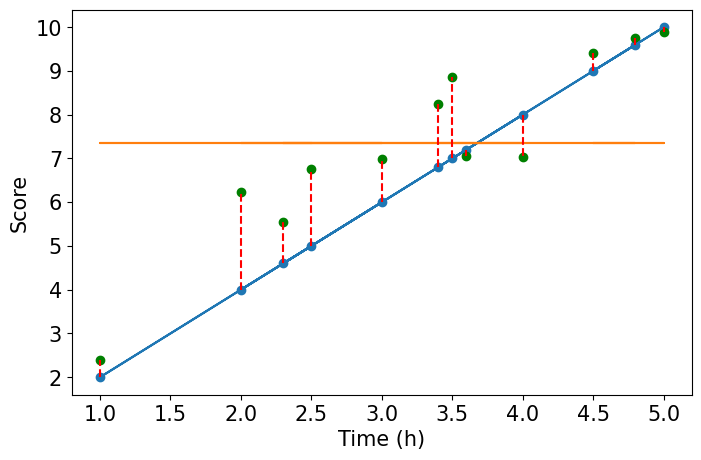

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(x, y_true, 'go')
plt.xlabel('Time (h)')
plt.ylabel('Score')
plt.plot(x, y_pred)
plt.plot(x, mean_line)
plt.scatter(x, y_pred)
for i in range(len(x)):
  plt.plot([x[i], x[i]], [y_pred[i], y_true[i]], 'r--')
plt.show()

### Implement by Python

In [29]:
def r2(y_true, y_pred):
  y_mean = np.mean(y_true)
  diff_pred = y_true - y_pred
  square_diff_pred = np.square(diff_pred)
  sum_square_diff_pred = np.sum(square_diff_pred)
  diff_y = y_mean - y_true
  square_diff_y = np.square(diff_y)
  sum_square_diff_y = np.sum(square_diff_y)
  return 1 - (sum_square_diff_pred / sum_square_diff_y)
print(r2(y_true, y_pred))

0.6560338457750637


### Implement by Sklearn

In [30]:
from sklearn.metrics import r2_score

r_squared = r2_score(y_true, y_pred)
print(r_squared)

0.6560338457750637


# Train/test split

In [31]:
from sklearn.datasets import make_regression
import numpy as np

In [32]:
X, y_true = make_regression(n_samples=150, n_features=1, noise=0.5, random_state=13)

In [33]:
def train_test_split(X, y, test_ratio):
    N = len(X)
    train_size = int(N * (1 - test_ratio))
    indices = np.arange(N)
    np.random.shuffle(indices)
    train_idx, test_idx = indices[:train_size], indices[train_size:]
    X_train, y_train = X[train_idx], y[train_idx]
    X_test, y_test = X[test_idx], y[test_idx]
    return X_train, X_test, y_train, y_test

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y_true, test_ratio=0.3)
print('Train size: ', len(y_train))
print('Test size: ', len(y_test))

Train size:  105
Test size:  45


In [35]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_true, test_size=0.3, random_state=seed)
print('Train size: ', len(y_train))
print('Test size: ', len(y_test))

Train size:  105
Test size:  45


In [36]:
from sklearn.neighbors import KNeighborsRegressor
k = 5
model = KNeighborsRegressor(n_neighbors=k)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
MSE = mean_squared_error(y_test, y_pred)
print(f'{k = } - {MSE = }')

k = 5 - MSE = 0.4669172222854923


## K fold validation

In [37]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=3)
for split_index, (train_index, test_index) in enumerate(kf.split(X)):
    print(f'Split {split_index + 1}')
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y_true[train_index], y_true[test_index]
    ## Call model.fit(X_train, y_train)
    ## Evaluate the model with model.predict(X_test)
    print('TRAIN: ', train_index[:10])
    print('TEST: ', test_index[:10])

Split 1
TRAIN:  [50 51 52 53 54 55 56 57 58 59]
TEST:  [0 1 2 3 4 5 6 7 8 9]
Split 2
TRAIN:  [0 1 2 3 4 5 6 7 8 9]
TEST:  [50 51 52 53 54 55 56 57 58 59]
Split 3
TRAIN:  [0 1 2 3 4 5 6 7 8 9]
TEST:  [100 101 102 103 104 105 106 107 108 109]


## Stratified K Fold

In [38]:
from sklearn.model_selection import StratifiedKFold
from sklearn.datasets import make_classification
X, y_true = make_classification(n_samples=100, n_classes=2, weights=[0.8, 0.2,], n_informative=10, random_state=seed)
print('Class weights in original data: ', np.unique(y_true, return_counts=True)[1]/len(y_true))
skf = StratifiedKFold(n_splits=3)
for split_index, (train_index, test_index) in enumerate(skf.split(X, y_true)):
    print(f'Split {split_index + 1}')
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y_true[train_index], y_true[test_index]
    ## Call model.fit(X_train, y_train)
    ## Evaluate the model with model.predict(X_test)
    print('Train weights: ', np.unique(y_train, return_counts=True)[1] / len(y_train)) 
    print('Test weights: ', np.unique(y_test, return_counts=True)[1] / len(y_test)) 

Class weights in original data:  [0.8 0.2]
Split 1
Train weights:  [0.8030303 0.1969697]
Test weights:  [0.79411765 0.20588235]
Split 2
Train weights:  [0.79104478 0.20895522]
Test weights:  [0.81818182 0.18181818]
Split 3
Train weights:  [0.80597015 0.19402985]
Test weights:  [0.78787879 0.21212121]
